# Аналитика подписочного VPN через HAPP

Показательный анализ на основе реального проекта автора: продажи через сайт и Telegram-бот, выдача ссылки подписки, её загрузка в HAPP и использование прокси. Для соблюдения конфиденциальности название `ShieldRoute`, данные и численные показатели публичной версии воссозданы синтетически.

## Краткий вывод

- Стабильное платящее ядро - **435** пользователей в каждом полном месяце; новые и временные пользователи считаются сверх него.
- Всего активных платящих пользователей по месяцам: **450–546**.
- Среди **217** новых оплаченных подписок полная 7-дневная активация - **64,5%**, загрузка ссылки в HAPP - **91,7%**.
- Активация по каналу продажи: Telegram-бот **67,5%**, сайт **56,1%**. Это описательное сравнение.

## Контекст и метод

Путь пользователя: **сайт / Telegram-бот → оплата → персональная ссылка → HAPP → прокси-сессии**. Собственного клиентского приложения у сервиса нет.

Подписка активирована за 7 дней, если ссылка загружена в HAPP, проведено не менее трёх успешных прокси-сессий в два разных UTC-дня и накоплено не менее 30 минут защищённого трафика.

Стабильное ядро - пользователи, чья подписка началась до периода наблюдения и оставалась активной до его конца. Численность ядра и различия вероятностей поведения по каналам заданы генератором. Все данные и результаты синтетические.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from vpn_analytics.data_quality import validate_dataset
from vpn_analytics.metrics import monthly_business_records, subscriber_activation_records

DATA_DIR = Path('../data/generated').resolve()
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"base": "#173F5F", "total": "#F2A900", "accent": "#2A9D8F"}

## Данные и контроль качества

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
quality = pd.DataFrame(
    [{"check": item.check_name, "failures": item.failure_count, "status": item.status} for item in validate_dataset(DATA_DIR)]
)
assert quality["failures"].sum() == 0
display(pd.Series(manifest["counts"], name="rows").to_frame())
display(quality)

,rows
dataset_periods,1
payments,3033
proxy_servers,18
proxy_sessions,34701
subscription_links,652
subscriptions,652
users,800


,check,failures,status
0,one_dataset_period,0,PASS
1,unique_user_id,0,PASS
2,unique_subscription_id,0,PASS
3,unique_subscription_link_id,0,PASS
4,unique_payment_id,0,PASS
5,unique_server_id,0,PASS
6,unique_proxy_session_id,0,PASS
7,subscriptions_have_users,0,PASS
8,one_subscription_per_user,0,PASS
9,one_link_per_subscription,0,PASS


In [3]:
activation = pd.DataFrame(subscriber_activation_records(DATA_DIR))
monthly = pd.DataFrame(monthly_business_records(DATA_DIR))
activation["link_fetched_7d"] = activation["first_link_fetched_at"].notna() & (
    activation["first_link_fetched_at"]
    < activation["subscription_started_at"] + pd.to_timedelta(7, unit="D")
)
monthly["month"] = pd.to_datetime(monthly["month_start"]).dt.strftime("%b %Y")
activation.head(3)

,user_id,subscription_id,registered_at,acquisition_channel,country,signup_source,sales_channel,plan,onboarding_variant,price_rub,...,protected_minutes_7d,traffic_gb_7d,failed_attempts_7d,total_attempts_7d,failure_rate_7d,p95_connection_time_ms,forced_disconnect_rate_7d,time_to_first_value_hours,activated_7d,link_fetched_7d
0,usr_000436,sub_000436,2026-06-20 07:29:57+00:00,organic,KZ,telegram_bot,telegram_bot,pro,treatment,220.0,...,66.711836,11.320284,0,2,0.000,1065.45,0.0,137.855797,False,True
1,usr_000438,sub_000438,2026-06-17 03:26:18+00:00,telegram_ads,RU,telegram_bot,telegram_bot,basic,treatment,130.0,...,246.792784,34.497341,1,8,0.125,1776.50,0.0,5.044938,True,True
2,usr_000439,sub_000439,2026-01-24 18:18:08+00:00,telegram_ads,RU,website,website,basic,control,130.0,...,342.087161,59.839050,0,8,0.000,1420.85,0.0,18.739193,True,True


## Результаты

In [4]:
link = activation["link_fetched_7d"]
success = activation["first_successful_connection_at"].notna()
funnel = pd.Series({
    "Оплачено": len(activation),
    "Ссылка загружена в HAPP": link.sum(),
    "Есть успешное подключение": (link & success).sum(),
    "3+ успешных сессии": (link & activation["successful_sessions_7d"].ge(3)).sum(),
    "Также 2+ активных дня": (link & activation["successful_sessions_7d"].ge(3) & activation["active_days_7d"].ge(2)).sum(),
    "Активация за 7 дней": activation["activated_7d"].sum(),
}, name="subscriptions").to_frame()
funnel["share_of_paid"] = funnel["subscriptions"] / len(activation)
funnel

,subscriptions,share_of_paid
Оплачено,217,1.000000
Ссылка загружена в HAPP,199,0.917051
Есть успешное подключение,186,0.857143
3+ успешных сессии,140,0.645161
Также 2+ активных дня,140,0.645161
Активация за 7 дней,140,0.645161


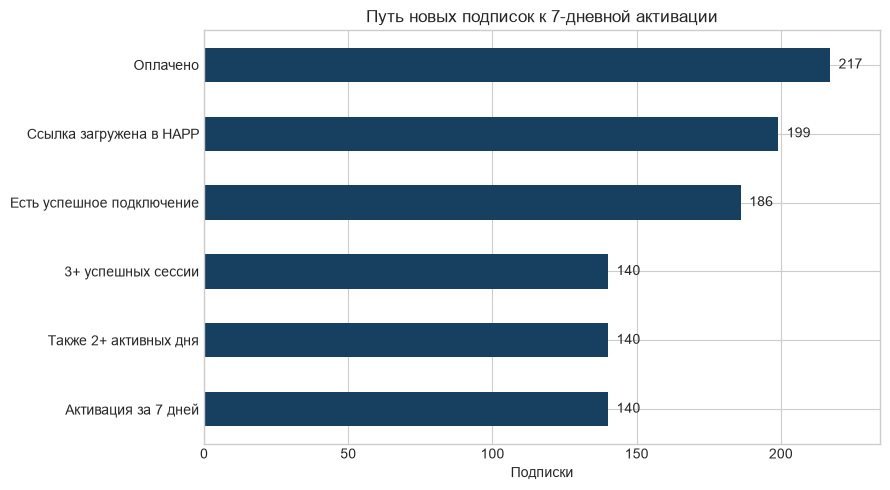

In [5]:
ax = funnel.iloc[::-1]["subscriptions"].plot.barh(figsize=(9, 5), color=COLORS["base"])
ax.set(title="Путь новых подписок к 7-дневной активации", xlabel="Подписки", ylabel="")
ax.set_xlim(0, len(activation) * 1.08)
for bar in ax.patches:
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2, f"{bar.get_width():.0f}", va="center")
plt.tight_layout();

In [6]:
monthly_view = monthly[[
    "month", "active_paid_subscribers", "monthly_active_paid_users",
    "regular_paid_users", "new_paid_users", "churned_users",
    "cash_revenue_rub", "normalized_mrr_rub", "connection_failure_rate", "traffic_gb",
]].copy()
monthly_view

,month,active_paid_subscribers,monthly_active_paid_users,regular_paid_users,new_paid_users,churned_users,cash_revenue_rub,normalized_mrr_rub,connection_failure_rate,traffic_gb
0,Jan 2026,450,450,435,15,0,72840.0,72840.0,0.041926,30365.664569
1,Feb 2026,463,457,435,13,4,74220.0,74220.0,0.043818,31106.789838
2,Mar 2026,502,482,435,43,7,79290.0,79290.0,0.041096,33694.511376
3,Apr 2026,559,513,435,64,21,86470.0,86470.0,0.046816,32927.562823
4,May 2026,563,523,435,25,29,86250.0,86250.0,0.051117,32305.278897
5,Jun 2026,591,546,435,57,34,89930.0,89930.0,0.055092,34725.443938


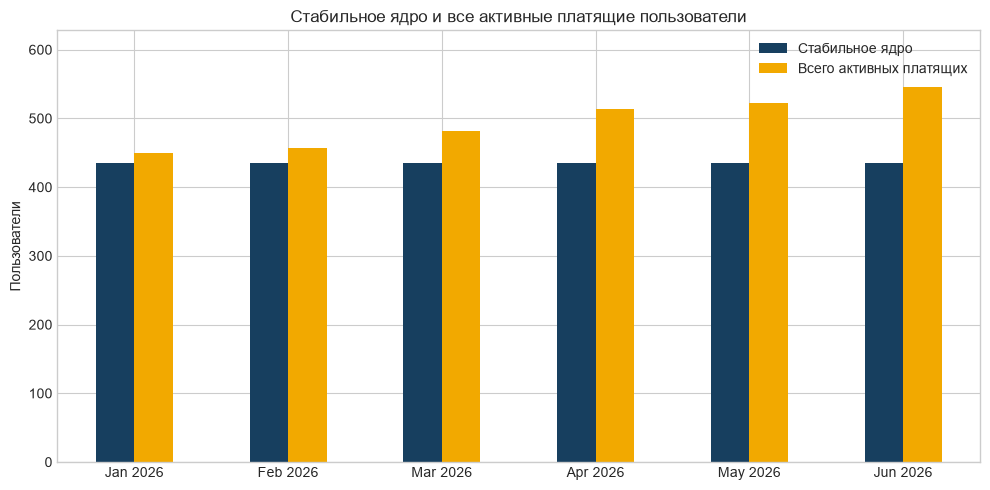

In [7]:
ax = monthly.set_index("month")[["regular_paid_users", "monthly_active_paid_users"]].plot(
    kind="bar", figsize=(10, 5), color=[COLORS["base"], COLORS["total"]]
)
ax.set(title="Стабильное ядро и все активные платящие пользователи", xlabel="", ylabel="Пользователи")
ax.legend(["Стабильное ядро", "Всего активных платящих"])
ax.set_ylim(0, monthly["monthly_active_paid_users"].max() * 1.15)
plt.xticks(rotation=0)
plt.tight_layout();

In [8]:
channels = activation.groupby("sales_channel").agg(
    paid_subscriptions=("subscription_id", "size"),
    link_fetch_rate=("link_fetched_7d", "mean"),
    activation_rate=("activated_7d", "mean"),
).sort_values("activation_rate", ascending=False)
channels

,paid_subscriptions,link_fetch_rate,activation_rate
sales_channel,,,
telegram_bot,160,0.918750,0.675000
website,57,0.912281,0.561404


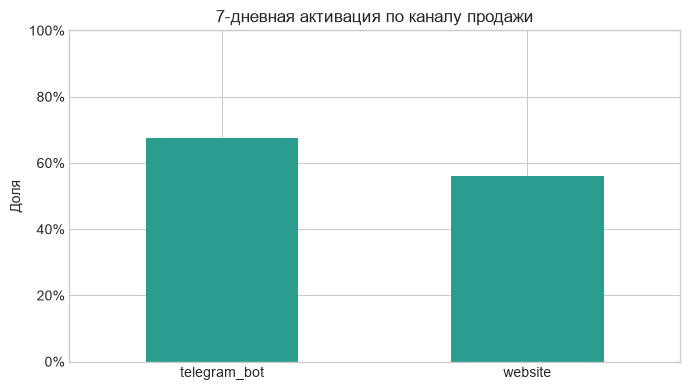

In [9]:
ax = channels["activation_rate"].plot.bar(figsize=(7, 4), color=COLORS["accent"])
ax.set(title="7-дневная активация по каналу продажи", xlabel="", ylabel="Доля")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.xticks(rotation=0)
plt.tight_layout();

## Выводы

1. Генератор удерживает заданное стабильное ядро в **435** пользователей ежемесячно.
2. В симуляции полная активация составляет **64,5%** при загрузке ссылки в HAPP у **91,7%** новых подписок. Этот разрыв иллюстрирует поиск гипотез улучшения онбординга, а не доказанный резерв реального бизнеса.
3. Различия Telegram-бота и сайта зависят от параметров генератора; наблюдательное сравнение не доказывает причинный эффект канала.
4. В реальном сервисе рядом с ростом базы следует контролировать failure rate, трафик, cash revenue и нормализованный MRR; здесь показан пример такого мониторинга.